# C3: Computer Vision

**FIT1061 Introduction to Artificial Intelligence — Credit Task 3**

In Week 9, the Gender Shades study revealed that facial recognition systems had error rates 34 times higher for dark-skinned women than for light-skinned men. In Week 10, you learned that AlexNet used gradient descent to learn features that classified images well enough to launch the deep learning era. But what does a machine actually "see"?

The answer is surprisingly simple. An image is just a grid of numbers. Computer vision applies mathematical operations — the same dot products from Week 8 — over that grid to extract **features**: measurable properties like edges, textures, and shapes that algorithms use to distinguish one image from another. When AlexNet won ImageNet in 2012, its first layer learned convolution filters almost identical to the hand-designed ones you will implement today.

This task takes you through the computer vision pipeline: from pixels to features. You'll implement a **2D convolution function** — the core operation behind every convolutional neural network — and discover how the choice of features determines what a model can see and what it misses.

> **Prerequisite:** P8 (Ready for Feedback). You'll reuse your understanding of NumPy arrays and dot products.

> **Credit level:** Less scaffolding than PASS tasks. We provide images, kernels, and plotting code; you implement the algorithms and interpret the results.

---

## Setup

In [39]:
import numpy as np
import matplotlib.pyplot as plt

from c3_helpers import (SMILEY, TEST_IMAGE, KERNELS,
                        HAND_TRACE_IMAGE, HAND_TRACE_KERNEL,
                        HAND_TRACE_CENTRE_EXPECTED,
                        make_face_image, clip_image,
                        show_image, show_image_grid,
                        show_kernel_results, show_edge_comparison)

print("Setup OK.")
print(f"SMILEY shape: {SMILEY.shape}, dtype: {SMILEY.dtype}")
print(f"TEST_IMAGE shape: {TEST_IMAGE.shape}")
print(f"Kernels available: {list(KERNELS.keys())}")

Setup OK.
SMILEY shape: (8, 8), dtype: uint8
TEST_IMAGE shape: (64, 64)
Kernels available: ['Box blur', 'Gaussian blur', 'Sharpen', 'Sobel (horiz)', 'Sobel (vert)']


---

## C3.1: Images as Arrays: Pixels Are Just Numbers

A digital image is a grid of numbers:
- **Grayscale**: a 2D array of shape `(height, width)`, values 0 (black) to 255 (white)
- **RGB colour**: a 3D array of shape `(height, width, 3)`, one channel each for red, green, blue

This is the same matrix structure from Week 8, but now each row is a row of pixels, not a data sample.

### Explore the smiley face

The helpers provide an 8×8 smiley-face image called `SMILEY`. Let's see what an image looks like as both numbers and pixels.

In [40]:
# Look at the smiley as a grid of numbers
print("The SMILEY image as numbers:")
print(SMILEY)
print()
print(f"Shape: {SMILEY.shape}  (8 rows, 8 columns)")
print(f"Data type: {SMILEY.dtype}")
print(f"Value range: [{SMILEY.min()}, {SMILEY.max()}]")
print()
print("0 = black, 255 = white. That's it — an image is just a spreadsheet.")

The SMILEY image as numbers:
[[  0   0   0   0   0   0   0   0]
 [  0 255 255   0   0 255 255   0]
 [  0 255 255   0   0 255 255   0]
 [  0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0]
 [  0 255   0   0   0   0 255   0]
 [  0   0 255 255 255 255   0   0]
 [  0   0   0   0   0   0   0   0]]

Shape: (8, 8)  (8 rows, 8 columns)
Data type: uint8
Value range: [0, 255]

0 = black, 255 = white. That's it — an image is just a spreadsheet.


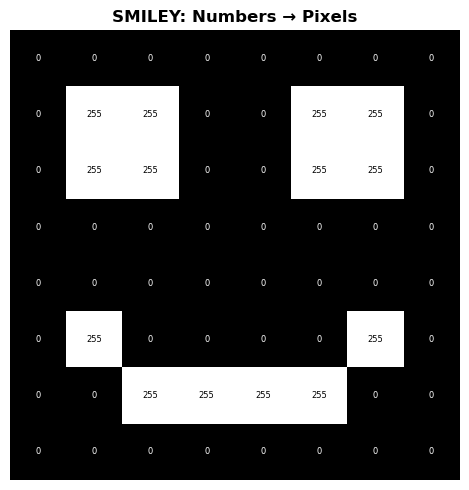

In [41]:
# Now see the same data as an image — with numbers overlaid
show_image(SMILEY, title="SMILEY: Numbers → Pixels", show_values=True)

### Pixel-level operations

Since images are arrays, we can manipulate them with array arithmetic:
- **Brightness**: add a constant to all pixels (shift values up or down)
- **Contrast**: multiply the deviation from the mean by a factor (stretch or compress the range)
- **Clipping**: after any operation, values must stay in [0, 255]: pixels can't be "blacker than black" or "whiter than white"

Every "filter" on your phone is just a mathematical operation on a grid of numbers.

**A `uint8` trap:** Images are stored as `uint8` (unsigned 8-bit integers, range 0 to 255). If you add 80 to 200, the result is 280, which *wraps around* to 24. Convert to a wider type (like `int16`) before doing arithmetic, then clip back. We provide `clip_image()` which clips values to [0, 255] and converts to `uint8` for you.

### Implement `adjust_brightness`

Add `amount` to every pixel and clip to [0, 255]. A positive amount makes the image brighter; negative makes it darker.

In [ ]:
def adjust_brightness(image, amount):
    """Adjust image brightness by adding a constant to all pixels.

    Args:
        image: 2D NumPy array (grayscale image).
        amount: Integer to add (positive = brighter, negative = darker).

    Returns:
        2D NumPy array with adjusted brightness, clipped to [0, 255], dtype uint8.
    """
    # --- YOUR CODE HERE ---
    # Hint: convert to int16 first (see the uint8 trap above),
    # add the amount, then clip_image().

    img_int16 = image.astype(np.int16) #i found this online - changes 8bit to 16
    img_adjusted = img_int16 + amount
    return clip_image(img_adjusted)

    # --- END YOUR CODE ---

Original pixel [1,1] (was 255): brighter = 255, darker = 175
Original pixel [0,0] (was 0):   brighter = 80, darker = 0
Check: brighter[0,0] should be 80: ✓
Check: brighter[1,1] should be 255 (clipped): ✓
Check: darker[0,0] should be 0 (clipped): ✓


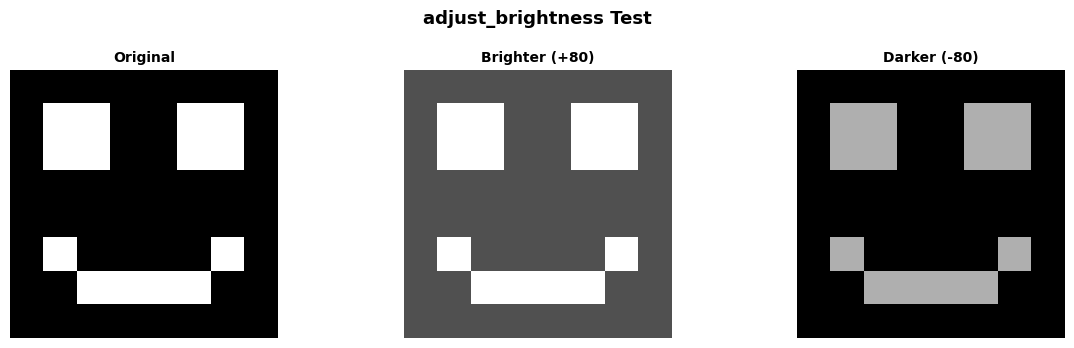

In [43]:
# Test adjust_brightness
if adjust_brightness(SMILEY, 80) is None:
    print("⚠ adjust_brightness returned None — implement it first!")
else:
    brighter = adjust_brightness(SMILEY, 80)
    darker = adjust_brightness(SMILEY, -80)

    # Check: original 0 + 80 = 80, original 255 + 80 = 255 (clipped)
    print(f"Original pixel [1,1] (was 255): brighter = {brighter[1,1]}, darker = {darker[1,1]}")
    print(f"Original pixel [0,0] (was 0):   brighter = {brighter[0,0]}, darker = {darker[0,0]}")
    print(f"Check: brighter[0,0] should be 80: {'✓' if brighter[0,0] == 80 else '✗'}")
    print(f"Check: brighter[1,1] should be 255 (clipped): {'✓' if brighter[1,1] == 255 else '✗'}")
    print(f"Check: darker[0,0] should be 0 (clipped): {'✓' if darker[0,0] == 0 else '✗'}")

    show_image_grid(
        [SMILEY, brighter, darker],
        ['Original', 'Brighter (+80)', 'Darker (-80)'],
        suptitle='adjust_brightness Test'
    )

### Implement `adjust_contrast`

Contrast measures how spread out the pixel values are. To increase contrast, we stretch each pixel's deviation from the mean:

$$\text{new\_pixel} = (\text{pixel} - \text{mean}) \times \text{factor} + \text{mean}$$

A factor > 1 increases contrast (dark pixels get darker, bright pixels get brighter). A factor < 1 decreases contrast (everything moves towards the mean grey).

In [44]:
def adjust_contrast(image, factor):
    """Adjust image contrast by scaling deviation from the mean.

    Args:
        image: 2D NumPy array (grayscale image).
        factor: Multiplier for contrast (>1 = more contrast, <1 = less).

    Returns:
        2D NumPy array with adjusted contrast, clipped to [0, 255], dtype uint8.
    """
    # --- YOUR CODE HERE ---
    # Hint: use the formula above. Work in float64 to avoid
    # integer arithmetic issues, then clip_image().
    # Convert to float64 for safe mathematical operations
    img_float = image.astype(np.float64) #same thing but float64
    mean_val = np.mean(img_float)
    img_adjusted = (img_float - mean_val) * factor + mean_val
    return clip_image(img_adjusted)

    # --- END YOUR CODE ---

Original range: [20.8, 233.2]
High contrast (×2) range: [0, 255]
Low contrast (×0.5) range: [49, 155]


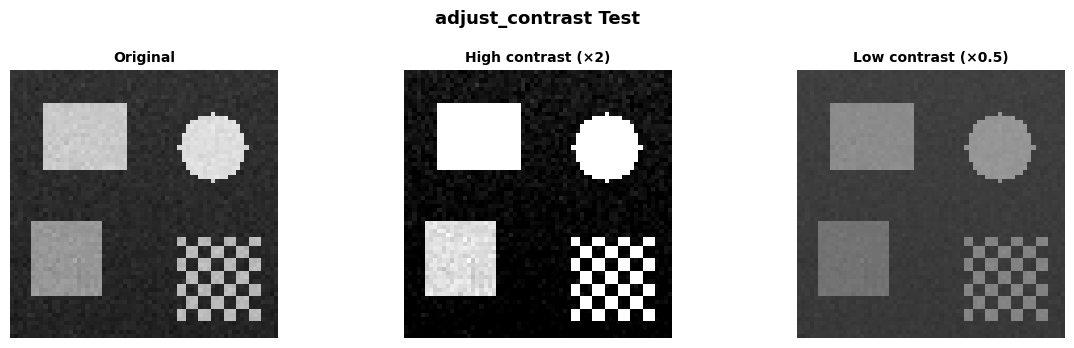

In [45]:
# Test adjust_contrast on the test image
if adjust_contrast(TEST_IMAGE, 2.0) is None:
    print("⚠ adjust_contrast returned None — implement it first!")
else:
    high_contrast = adjust_contrast(TEST_IMAGE, 2.0)
    low_contrast = adjust_contrast(TEST_IMAGE, 0.5)

    print(f"Original range: [{TEST_IMAGE.min():.1f}, {TEST_IMAGE.max():.1f}]")
    print(f"High contrast (×2) range: [{high_contrast.min()}, {high_contrast.max()}]")
    print(f"Low contrast (×0.5) range: [{low_contrast.min()}, {low_contrast.max()}]")

    show_image_grid(
        [TEST_IMAGE, high_contrast, low_contrast],
        ['Original', 'High contrast (×2)', 'Low contrast (×0.5)'],
        suptitle='adjust_contrast Test'
    )

> **Why this matters:** You just manipulated what a machine "sees": brightness and contrast are the raw signal that every computer vision algorithm works with. In C3.2, you'll discover that this signal determines whose face a machine can detect and whose it misses.

---

## Warm-up: the trace from the whiteboard

In the lecture we convolved **one window by hand**: laid the kernel over a 3x3 patch, multiplied
matching cells, and added. Work through it yourself to warm up before you implement convolution below.

Stuck? This is the exact example from the lecture: revisit the slides or the workshop.

A 3x3 window (a patch of the image) and the kernel:

```
   window              kernel
  2   3   1          1   2   1
  0   4   2          2   4   2
  1   1   0          1   2   1
```

Multiply each window cell by the matching kernel cell, then add up all nine products:

- Row 0:  2x1 + 3x2 + 1x1  = 9
- Row 1:  0x2 + 4x4 + 2x2  = 20
- Row 2:  1x1 + 1x2 + 0x1  = 3
- **Total (the output pixel)** = 32

That single number replaces the centre pixel. Convolution slides this window over every pixel,
which is exactly what you will implement below.


---

## C3.2: Convolution: The Core Operation of Computer Vision

**Convolution** moves a small matrix (called a **kernel** or **filter**) across the image, one position at a time. At each position, it computes the **dot product** between the kernel and the image patch beneath it: element-wise multiply, then sum.

Here is how the kernel moves across a 5×5 image. At each position, it covers a 3×3 patch:

```
Position (0,0):        Position (0,1):        Position (0,2):
[K  K  K]  .  .        . [K  K  K]  .         .  . [K  K  K]
[K  K  K]  .  .   →    . [K  K  K]  .    →    .  . [K  K  K]
[K  K  K]  .  .        . [K  K  K]  .         .  . [K  K  K]
 .  .  .   .  .         .  .  .  .  .          .  .  .  .  .
 .  .  .   .  .         .  .  .  .  .          .  .  .  .  .

At each position: output[i,j] = sum of (patch × kernel)
```

This is the dot product from Week 8, applied *spatially*: each position in the output is a local weighted sum.

$$\text{output}[i, j] = \sum_{m} \sum_{n} \text{image}[i+m, j+n] \times \text{kernel}[m, n]$$

Different kernels detect different **features** (measurable properties of the image):
- **Blur kernel**: averages nearby pixels (smooths noise)
- **Sharpen kernel**: enhances differences between a pixel and its neighbours
- **Edge-detection kernel (Sobel)**: responds to rapid changes in intensity. Named after Irwin Sobel, who proposed these gradient-approximation filters in 1968: they remain a standard tool in computer vision today.

### Hand-trace: convolution by hand

Before coding, let's trace one convolution step to see that it's just a dot product.

**Image:** A 5×5 grid with one bright pixel (200) in the centre, all others 10.

**Kernel:** A 3×3 box blur (each entry = 1/9, so it averages the 9 neighbours).

```
Image patch (centre 3×3):     Kernel:
[ 10  10  10 ]                [ 1/9  1/9  1/9 ]
[ 10 200  10 ]    ×           [ 1/9  1/9  1/9 ]    = ?
[ 10  10  10 ]                [ 1/9  1/9  1/9 ]

Element-wise multiply and sum:
(10×1/9)*8 + (200×1/9)*1 = 80/9 + 200/9 = 280/9 ≈ 31.1

The bright pixel's energy is spread across its neighbours.
```

Run the cell below to verify the hand-trace calculation. You don't need to modify it: it confirms the calculation you traced by hand.

In [46]:
# Verify the hand-trace
print("Hand-trace image (5×5, one bright pixel in centre):")
print(HAND_TRACE_IMAGE.astype(int))
print()
print("Blur kernel (3×3 average):")
print(np.round(HAND_TRACE_KERNEL, 3))
print()

# Manual calculation for the centre pixel [2, 2]
centre_patch = HAND_TRACE_IMAGE[1:4, 1:4]
manual_result = np.sum(centre_patch * HAND_TRACE_KERNEL)
print(f"Centre patch:\n{centre_patch.astype(int)}")
print(f"Element-wise multiply and sum: {manual_result:.4f}")
print(f"Expected: {HAND_TRACE_CENTRE_EXPECTED:.4f}")
print(f"Check: {'✓ Match!' if abs(manual_result - HAND_TRACE_CENTRE_EXPECTED) < 0.01 else '✗ Mismatch'}")

Hand-trace image (5×5, one bright pixel in centre):
[[ 10  10  10  10  10]
 [ 10  10  10  10  10]
 [ 10  10 200  10  10]
 [ 10  10  10  10  10]
 [ 10  10  10  10  10]]

Blur kernel (3×3 average):
[[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]

Centre patch:
[[ 10  10  10]
 [ 10 200  10]
 [ 10  10  10]]
Element-wise multiply and sum: 31.1111
Expected: 31.1111
Check: ✓ Match!


### Implement `convolve2d`

This is the core function. It slides the kernel over every position in the image, computes the dot product at each location, and returns the output image.

**Why zero-padding?** Without padding, the kernel hangs off the edges of the image and the output shrinks by `(kernel_size - 1)` pixels in each dimension. Zero-padding (surrounding the image with a border of zeros) preserves the original size.

In [47]:
def convolve2d(image, kernel):
    """Apply 2D convolution to a grayscale image.

    Args:
        image: 2D NumPy array (grayscale image).
        kernel: 2D NumPy array (small, e.g. 3×3).

    Returns:
        2D NumPy array (convolved image, same size as input via zero-padding).
    """
    # --- YOUR CODE HERE ---
    # Slide the kernel over every pixel; you'll need to zero-pad the border
    # so the output size matches the input.

    img_h, img_w = image.shape
    k_h, k_w = kernel.shape
    pad_h = k_h // 2
    pad_w = k_w // 2

    padded_image = np.zeros((img_h + 2 * pad_h, img_w + 2 * pad_w), dtype=np.float64)
    padded_image[pad_h : pad_h + img_h, pad_w : pad_w + img_w] = image.astype(np.float64) #putting image in the middle

    output = np.zeros((img_h, img_w), dtype=np.float64)
    for i in range(img_h):
        for j in range(img_w):
            patch = padded_image[i : i + k_h, j : j + k_w]
            output[i, j] = np.sum(patch * kernel) #dot product
    return output

    # --- END YOUR CODE ---

In [48]:
# Test convolve2d on the hand-trace image
if convolve2d(HAND_TRACE_IMAGE, HAND_TRACE_KERNEL) is None:
    print("⚠ convolve2d returned None — implement it first!")
else:
    result = convolve2d(HAND_TRACE_IMAGE, HAND_TRACE_KERNEL)
    print("Convolution result on hand-trace image:")
    print(np.round(result, 2))
    print()
    centre_val = result[2, 2]
    print(f"Centre pixel: {centre_val:.4f}")
    print(f"Expected:     {HAND_TRACE_CENTRE_EXPECTED:.4f}")
    print(f"Check: {'✓ Match!' if abs(centre_val - HAND_TRACE_CENTRE_EXPECTED) < 0.01 else '✗ Mismatch — check your implementation'}")
    print()
    print(f"Output shape: {result.shape} (same as input: {HAND_TRACE_IMAGE.shape})")
    print("The sharp bright spot has been blurred — its energy is spread across neighbours.")

Convolution result on hand-trace image:
[[ 4.44  6.67  6.67  6.67  4.44]
 [ 6.67 31.11 31.11 31.11  6.67]
 [ 6.67 31.11 31.11 31.11  6.67]
 [ 6.67 31.11 31.11 31.11  6.67]
 [ 4.44  6.67  6.67  6.67  4.44]]

Centre pixel: 31.1111
Expected:     31.1111
Check: ✓ Match!

Output shape: (5, 5) (same as input: (5, 5))
The sharp bright spot has been blurred — its energy is spread across neighbours.


### Apply all five kernels

Now apply your `convolve2d` to the test image with each of the five provided kernels. The helper function `show_kernel_results` will display them side-by-side.

In [49]:
# Display the five standard kernels
print("Standard Computer Vision Kernels:")
print("=" * 40)
for name, k in KERNELS.items():
    print(f"\n{name}:")
    print(np.round(k, 3))

Standard Computer Vision Kernels:

Box blur:
[[0.111 0.111 0.111]
 [0.111 0.111 0.111]
 [0.111 0.111 0.111]]

Gaussian blur:
[[0.062 0.125 0.062]
 [0.125 0.25  0.125]
 [0.062 0.125 0.062]]

Sharpen:
[[ 0. -1.  0.]
 [-1.  5. -1.]
 [ 0. -1.  0.]]

Sobel (horiz):
[[-1. -2. -1.]
 [ 0.  0.  0.]
 [ 1.  2.  1.]]

Sobel (vert):
[[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]


### Predict before running

Look at the five kernels above. Before running the next cell, write your predictions:

1. **Box blur**: all values are 1/9. What will this do to sharp edges in the image?
2. **Sharpen**: centre value is 5, neighbours are −1. What happens to a pixel that matches its neighbours? What about one that's very different from them?
3. **Sobel (horizontal)**: top row negative, bottom row positive. What kind of image feature will produce a large (positive or negative) output?

1. The sharp edges become more closer to each other and thus the image is blurred.
2. Similar edges stay the same, different edges get multiplied and end up more different.
3. An image dividing the bright and dark regions by a horizontal line will produce a large output.

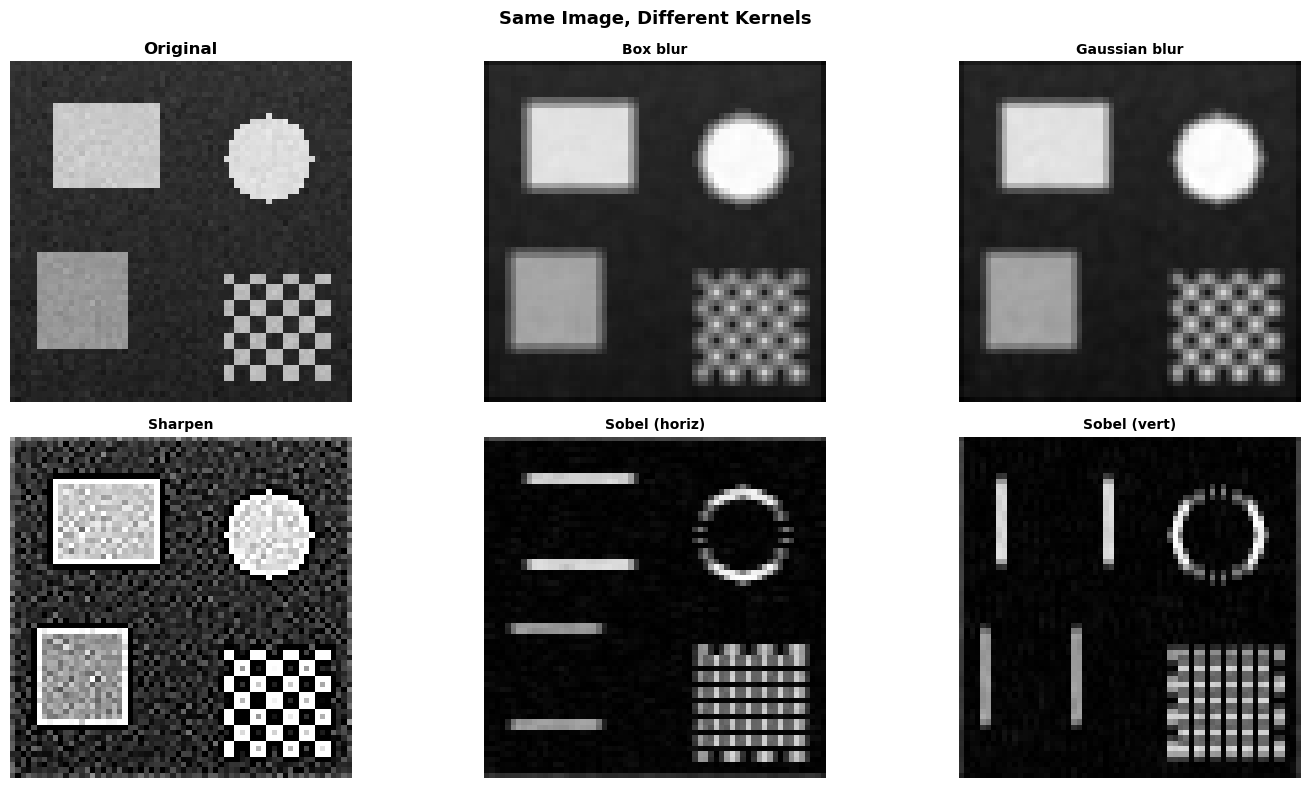

Blur: smooths noise, loses sharp edges.
Sharpen: enhances edges, amplifies noise too.
Sobel: detects edges — bright where intensity changes rapidly.


In [50]:
# Apply all kernels to the test image
if convolve2d(HAND_TRACE_IMAGE, HAND_TRACE_KERNEL) is None:
    print("⚠ Implement convolve2d first!")
else:
    show_kernel_results(TEST_IMAGE, convolve2d,
                        title="Same Image, Different Kernels")
    print("Blur: smooths noise, loses sharp edges.")
    print("Sharpen: enhances edges, amplifies noise too.")
    print("Sobel: detects edges — bright where intensity changes rapidly.")

### Edge detection: from pixels to features

Edges are the most fundamental features in computer vision. An edge is where pixel values change rapidly: the boundary between objects.

To get a full edge map, combine horizontal and vertical Sobel filters:

$$\text{edge\_magnitude} = \sqrt{G_x^2 + G_y^2}$$

where $G_x$ is the horizontal Sobel output and $G_y$ is the vertical Sobel output.

Implement `edge_magnitude` below using your `convolve2d` function and the Sobel kernels from `KERNELS`.

In [51]:
def edge_magnitude(image):
    """Compute edge magnitude using Sobel filters.

    Args:
        image: 2D NumPy array (grayscale image).

    Returns:
        2D NumPy array — the magnitude of the gradient at each pixel.
    """
    # --- YOUR CODE HERE ---
    # Combine the horizontal and vertical Sobel responses into a single
    # edge strength per pixel.
    # Convolve the image with both the horizontal and vertical Sobel kernels
    gx = convolve2d(image, KERNELS['Sobel (horiz)'])
    gy = convolve2d(image, KERNELS['Sobel (vert)'])
    magnitude = (gx**2 + gy**2) ** 0.5
    return magnitude
    # --- END YOUR CODE ---

Edge magnitude range: [0.3, 819.1]
Mean edge strength: 130.6


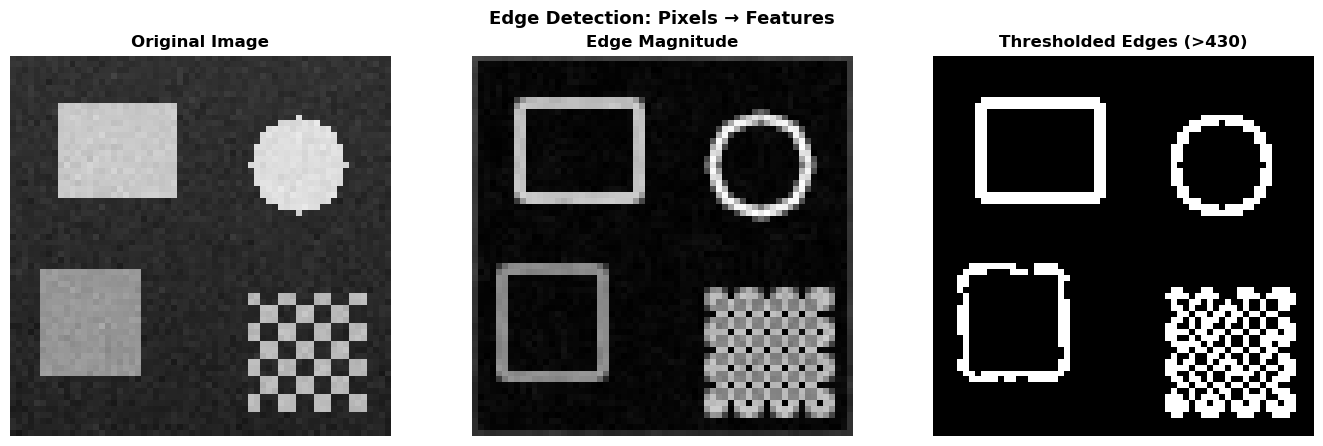

The edge map captures the STRUCTURE of the image.
It discards brightness and texture, keeping only boundaries.


In [52]:
# Test edge_magnitude
if edge_magnitude(TEST_IMAGE) is None:
    print("⚠ edge_magnitude returned None — implement it first!")
else:
    edges = edge_magnitude(TEST_IMAGE)
    print(f"Edge magnitude range: [{edges.min():.1f}, {edges.max():.1f}]")
    print(f"Mean edge strength: {np.mean(edges):.1f}")

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.5))

    ax1.imshow(TEST_IMAGE, cmap='gray', vmin=0, vmax=255)
    ax1.set_title('Original Image', fontweight='bold')
    ax1.axis('off')

    ax2.imshow(edges, cmap='gray')
    ax2.set_title('Edge Magnitude', fontweight='bold')
    ax2.axis('off')

    # Threshold the edges to get a clean edge map
    threshold = np.percentile(edges, 85)
    edge_binary = (edges > threshold).astype(np.uint8) * 255
    ax3.imshow(edge_binary, cmap='gray')
    ax3.set_title(f'Thresholded Edges (>{threshold:.0f})', fontweight='bold')
    ax3.axis('off')

    plt.suptitle('Edge Detection: Pixels → Features', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print("The edge map captures the STRUCTURE of the image.")
    print("It discards brightness and texture, keeping only boundaries.")

### The fairness angle: what does a machine "see"?

The Gender Shades study (Week 9) found that facial recognition systems had 34× higher error rates on dark-skinned women. One mechanism behind this: **edge detection depends on contrast** (the difference between an object and its background). When skin tone is close to the background tone, edges are weaker.

Run your `edge_magnitude` function on three "face" images with different contrast levels and observe the disparity.

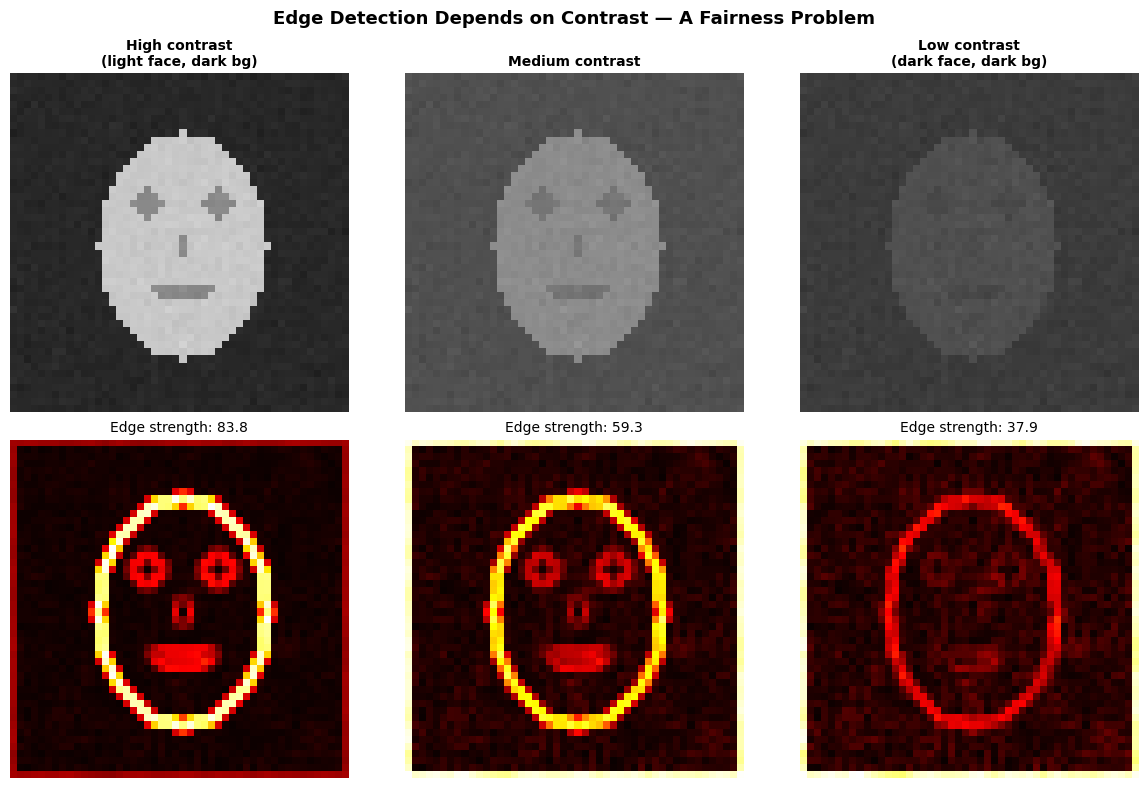

Edge strength — High contrast: 83.8, Medium: 59.3, Low: 37.9
Ratio (high / low): 2.2x

Same shape, same algorithm — but the low-contrast face
produces weaker edge features. A classifier trained on
mostly high-contrast faces will struggle with low-contrast ones.

This is one mechanism behind the Gender Shades disparity:
the features themselves encode an assumption about contrast
that works better for some skin tones than others.


In [53]:
# Compare edge detection on faces with different contrast levels
if edge_magnitude(TEST_IMAGE) is None:
    print("⚠ Implement edge_magnitude first!")
else:
    show_edge_comparison(convolve2d, edge_magnitude)
    print()
    print("This is one mechanism behind the Gender Shades disparity:")
    print("the features themselves encode an assumption about contrast")
    print("that works better for some skin tones than others.")

### Experiment: Does blurring help?

A common image processing pipeline blurs an image before detecting edges (to reduce noise). But does this "help" all faces equally? Run the cell below and observe what happens to the low-contrast face.

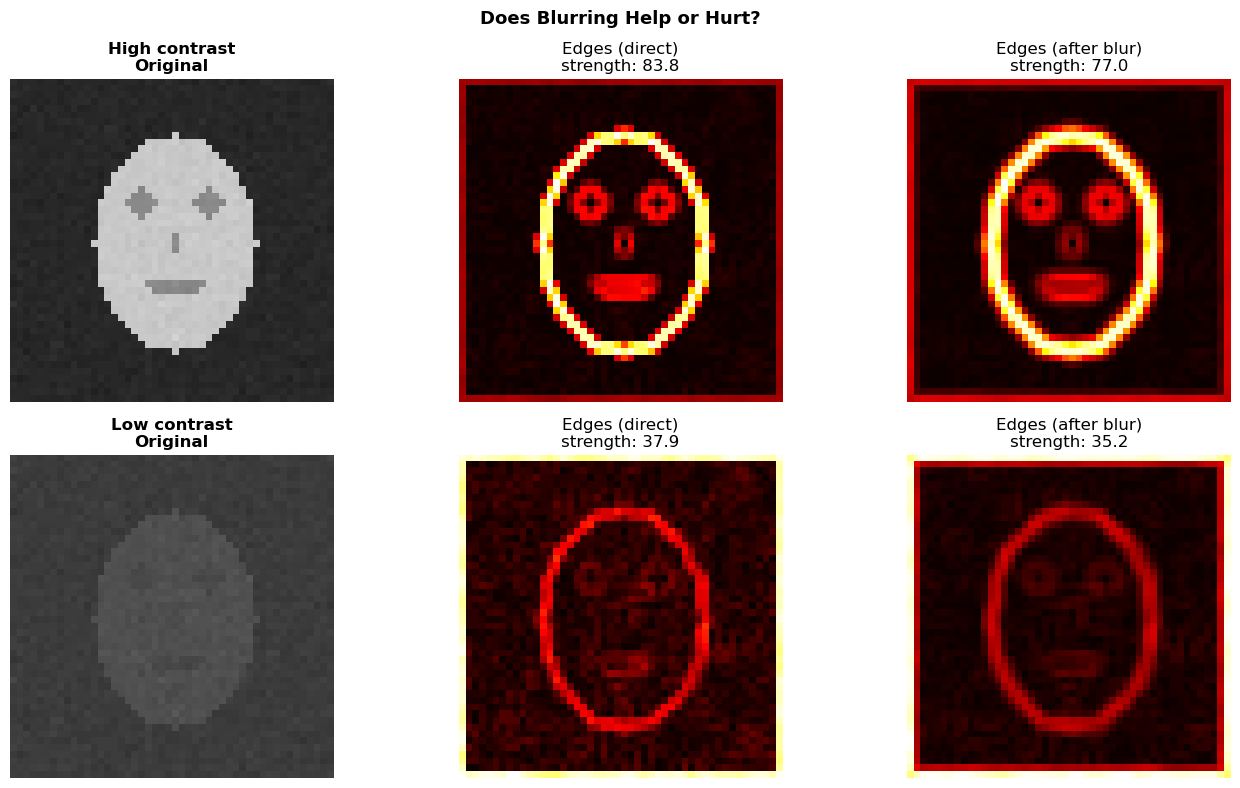

Blurring reduces noise — but also weakens edges.
For the low-contrast face, already-weak edges get even weaker.
A 'standard' preprocessing step can widen the gap between faces.


In [54]:
# Experiment: blur before edge detection — does it help equally?
if edge_magnitude(TEST_IMAGE) is None:
    print("⚠ Implement edge_magnitude first!")
else:
    blur_kernel = KERNELS['Gaussian blur']
    high_face = make_face_image(200, 40)
    low_face = make_face_image(80, 60)

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))
    for i, (face, label) in enumerate([(high_face, 'High contrast'),
                                        (low_face, 'Low contrast')]):
        blurred = clip_image(convolve2d(face, blur_kernel))
        edges_direct = edge_magnitude(face)
        edges_blurred = edge_magnitude(blurred)

        axes[i, 0].imshow(face, cmap='gray', vmin=0, vmax=255)
        axes[i, 0].set_title(f'{label}\nOriginal', fontweight='bold')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(edges_direct, cmap='hot')
        axes[i, 1].set_title(f'Edges (direct)\nstrength: {np.mean(edges_direct):.1f}')
        axes[i, 1].axis('off')

        axes[i, 2].imshow(edges_blurred, cmap='hot')
        axes[i, 2].set_title(f'Edges (after blur)\nstrength: {np.mean(edges_blurred):.1f}')
        axes[i, 2].axis('off')

    plt.suptitle('Does Blurring Help or Hurt?', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

    print("Blurring reduces noise — but also weakens edges.")
    print("For the low-contrast face, already-weak edges get even weaker.")
    print("A 'standard' preprocessing step can widen the gap between faces.")

### Connecting the dots: from this course to modern AI

Fill in the "Connection" column before reading the paragraph below.

| Week | Concept | How does it connect to computer vision? |
|------|---------|----------------------------------------|
| W8 | Dot product, weighted sums | convolution computes weighted sums of nearby pixels using a kernel |
| W9 | Fairness metrics, Gender Shades | CV systems can be biased, so fairness metrics help evaluate whether models work equally well for different groups |
| W10 | Gradient descent | Used to train computer vision models by minimizing prediction error and updating weights |
| **W11** | **Convolution** | **The core CV operation** |

**After filling in the table**, read on:

Convolution *is* a local dot product: each output pixel is a weighted sum of a small patch of the input. AlexNet's first layer learned filters almost identical to the Sobel filters you applied by hand. The revolution was automating feature design with gradient descent, not inventing a new operation.

**Scale note:** Your test image has ~4,000 pixels. An ImageNet image has ~150,000. AlexNet processed 1.2 million of them: this is why GPUs revolutionised deep learning. The operation is the same; what changed is scale and who designs the kernels.

---

## Check Your Understanding

In [55]:
from jupyterquiz import display_quiz

c4_quiz = [
    {
        "question": "What does 2D convolution compute at each position in the output image?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "The dot product between the kernel and the image patch beneath it — element-wise multiply and sum.", "correct": True, "feedback": "Correct! Convolution at each position extracts the patch under the kernel, multiplies element-wise, and sums. This is exactly the dot product from Week 8, applied at every spatial location."},
            {"answer": "The maximum pixel value in the neighbourhood.", "correct": False, "feedback": "That would be max pooling, not convolution. Convolution computes a weighted sum (dot product) of the patch and kernel."},
            {"answer": "The difference between the current pixel and the average of its neighbours.", "correct": False, "feedback": "Some kernels (like Sharpen) have this effect, but convolution itself is a general operation — it computes the dot product between the kernel and the patch. The kernel determines what is computed."},
            {"answer": "The pixel value of the original image divided by the kernel size.", "correct": False, "feedback": "That's not what convolution does. Convolution multiplies each pixel in the patch by the corresponding kernel value and sums the results."}
        ]
    },
    {
        "question": "Why does the Sobel edge detector produce weaker responses on low-contrast images?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "The Sobel kernel computes differences between neighbouring pixels. When contrast is low, these differences are small, producing weak edge responses.", "correct": True, "feedback": "Correct! Edge detection fundamentally measures how rapidly pixel values change. Low contrast means small differences between object and background, which means weak edges. This is one mechanism behind the Gender Shades disparity."},
            {"answer": "The Sobel kernel only works on images with pixel values above 128.", "correct": False, "feedback": "The Sobel kernel works on any pixel values. The issue is contrast (difference between regions), not absolute brightness."},
            {"answer": "Low-contrast images have fewer pixels, so there are fewer edges to detect.", "correct": False, "feedback": "Low-contrast images have the same number of pixels. The issue is that the differences between neighbouring pixel values are small, not that there are fewer pixels."},
            {"answer": "The zero-padding introduces artifacts that cancel out the edges.", "correct": False, "feedback": "Zero-padding affects the image borders but doesn't explain weak edges in the interior. The weak response is due to small intensity differences between the object and background."}
        ]
    },
    {
        "question": "AlexNet's first convolutional layer learned filters that look like Sobel edge detectors. What does this tell us?",
        "type": "multiple_choice",
        "answers": [
            {"answer": "Edge detection is so fundamental that gradient descent rediscovered it from data — the operation (convolution) is the same whether kernels are hand-designed or learned.", "correct": True, "feedback": "Correct! The core operation in both classical CV and deep learning is convolution. The difference is who designs the kernels: humans (hand-crafted) or gradient descent (learned). The fact that learned filters converge to edge detectors validates decades of hand-designed computer vision."},
            {"answer": "AlexNet copied the Sobel filter from a textbook and didn't actually learn anything new.", "correct": False, "feedback": "AlexNet's filters were learned via gradient descent from millions of images, not copied. The fact that they resemble Sobel filters is remarkable precisely because they emerged from data, not from human design."},
            {"answer": "Edge detection is the only useful operation in computer vision.", "correct": False, "feedback": "Edge detection is fundamental but not the only operation. AlexNet's deeper layers learned texture, shape, and object-part detectors. But the first layer learning edge detectors shows it's the natural starting point."},
            {"answer": "Gradient descent always produces Sobel filters regardless of the training data.", "correct": False, "feedback": "The learned filters depend on the training data. AlexNet also learned colour-opponent and texture filters. The edge detectors emerged because edges are universally useful features for image classification."}
        ]
    }
]

display_quiz(c4_quiz, shuffle_answers=True)

<IPython.core.display.Javascript object>

---

## C3.3: Reflection: What Does a Machine "See"?

Write a reflection (300--500 words) engaging with this prompt:

> *"Gender Shades showed facial recognition fails on dark-skinned faces. What does a machine 'see,' and whose faces are in the training data?"*

In Week 9 you examined fairness in classification. This time, connect the technical to the social:
- You've now seen one mechanism behind the disparity: **edge detection depends on contrast**, and contrast depends on skin tone relative to background. How does this technical fact connect to the Gender Shades findings?
- The training data for ImageNet was 70% from the US and UK. How does this affect what the model learns to "see"?
- Can we fix this by adding more diverse training data, or is the problem deeper: embedded in the features themselves?
- Should facial recognition be deployed in public spaces if it works well for 95% of people but fails for 5%?

> **Required reading:** Joy Buolamwini and Timnit Gebru, "Gender Shades" (2018).

Edge detection algorithms such as Sobel's filter are heavily dependent on contrast for detecting the boundaries of structures in an image. They calculate the gradient magnitude by taking the intensity of each pixel of the patch and measuring how quickly that changes across the patch. If the average value of the pixels in a face is dark (e.g. black) and the background is also dark (e.g. black) or the lighting is not bright, the difference in the values between adjacent pixels is very small. This means that the algorithm is mathematically "blind" to the lower level edges, so that these lower level ones are lost before the higher level layers of a neural network can even process them. This technical constraint is greatly amplifiedd by the training data's composition. About 70% of the images in the ImageNet dataset, a key milestone in the development of today's AI, were sourced from the US and the UK. The models are thus trained to detect faces that statistically match the few face images that were used to train them (which are mostly lighter-skinned people). The machine "sees" only what it was trained to see, and is very sensitive to the contrast gradients associated with lighter skin tones, but not those associated with darker skin tones.

A fellow student put a suggestion to the idea in the debate: collect more varied training data, and so get rid of these biases. Balancing datasets is an essential step, but it's probably more complex than simply representing datasets. The mathematical essence of feature extraction, such as edge detection, standard blurring pipelines, is inherently difficult in low contrast situations, and simply providing the model with more variety of images will not overcome the algorithmic limitation. The features extracted in themselves include a lighting and contrast assumption that make some skin tones worse than others in terms of pure math. The fact that there are flaws in the system, and that they are affecting 5% of the population, which is disproportionately in certain marginalized groups, means it's very unethical to put it in public areas when it fails for 5% of the population. The overall 95% accuracy rate fails to reveal that the system may have a very low accuracy rate for some intersecting identities. In high stakes contexts such as policing, such "false positives" and "false negatives" result in systemic discrimination. These systems remain structurally biased and unsuitable for public deployment until the processes used for feature extraction in mathematics and data representations are both fair.

---

## Results Table

| Operation / Function | Input | Key Output | Your Value |
|---------------------|-------|------------|------------|
| `adjust_brightness(SMILEY, 80)` | pixel [0,0] (was 0) | Expected: 80 |80 |
| `adjust_brightness(SMILEY, 80)` | pixel [1,1] (was 255) | Expected: 255 (clipped) | 255|
| `convolve2d` hand-trace | centre pixel | Expected: 31.11 |31.11 |
| `edge_magnitude(TEST_IMAGE)` | mean edge strength |  |130.6 |
| Edge comparison | high contrast face | edge strength |83.8 |
| Edge comparison | medium contrast face | edge strength | 59.3|
| Edge comparison | low contrast face | edge strength |37.9 |
| Edge comparison | high/low ratio | | 2.2|

---

## Submission Checklist

- [ ] **C3.1:** `adjust_brightness` function implemented and tested
- [ ] **C3.1:** `adjust_contrast` function implemented and tested
- [ ] **C3.1:** Visual comparison of brightness and contrast adjustments
- [ ] **C3.2:** Hand-trace of convolution verified against computed output
- [ ] **C3.2:** `convolve2d` function implemented and working
- [ ] **C3.2:** Side-by-side comparison of all five kernels on test image
- [ ] **C3.2:** `edge_magnitude` function implemented
- [ ] **C3.2:** Edge detection compared across high/medium/low contrast images
- [ ] **C3.3:** Reflection on Gender Shades and feature extraction bias (300--500 words)
- [ ] Results table filled in
- [ ] All files uploaded to OnTrack

---

> **AI use policy (Credit level):**
> You may use AI to explain concepts or debug errors. Do not use AI to generate implementations or written analysis. Cite all AI use.

---

*FIT1061 Credit Task 3: Computer Vision*